# 🤖 Cyberdyne Systems — Clasificación de dígitos con MNIST

**Parte 1 del desafío Skynet.** Entrenamos un perceptrón multicapa con TensorFlow/Keras. Elegimos Keras por su API clara y porque `model.fit()` registra loss y accuracy de entrenamiento y validación en cada epoch.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)           # reproducibilidad

# Hiperparámetros base IDÉNTICOS para todos los experimentos
EPOCHS, BATCH, LR = 10, 128, 0.01

# PARTE 1 — MNIST

## 1. Carga y exploración visual

x_train: (60000, 28, 28) uint8 | x_test: (10000, 28, 28)
Rango de píxeles: 0 - 255


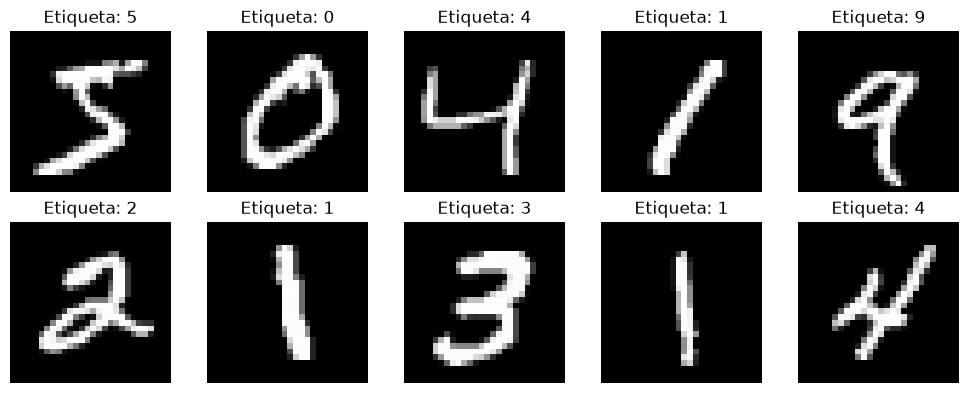

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
nombres_mnist = [str(i) for i in range(10)]

print("x_train:", x_train.shape, x_train.dtype, "| x_test:", x_test.shape)
print("Rango de píxeles:", x_train.min(), "-", x_train.max())

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(f"Etiqueta: {y_train[i]}")
    ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Preprocesamiento

Normalizamos a [0, 1] (÷255), aplanamos 28×28 → 784 (las capas `Dense` esperan un vector) y separamos 10.000 imágenes de train para validación. El test se usa solo al final.

In [3]:
def preparar(x_tr, y_tr, x_te):
    x_tr = x_tr.astype("float32").reshape(-1, 784) / 255.0
    x_te = x_te.astype("float32").reshape(-1, 784) / 255.0
    return x_tr[:-10000], y_tr[:-10000], x_tr[-10000:], y_tr[-10000:], x_te

x_tr, y_tr, x_val, y_val, x_te = preparar(x_train, y_train, x_test)
print("train:", x_tr.shape, "| val:", x_val.shape, "| test:", x_te.shape)
print("Rango tras normalizar:", x_tr.min(), "-", x_tr.max())

train: (50000, 784) | val: (10000, 784) | test: (10000, 784)
Rango tras normalizar: 0.0 - 1.0


## 3. Arquitectura

`Input(784) → Dense(128, activación) → Dense(10, softmax)`

- **1 capa oculta de 128 neuronas**: cumple el rango 1–2 capas y alcanza para esta tarea sin sobredimensionar.
- **Softmax con 10 salidas**: una probabilidad por clase.
- **`sparse_categorical_crossentropy`**: acepta las etiquetas como enteros (0–9).

In [4]:
def construir_modelo(activacion, optimizador):
    model = keras.Sequential([
        keras.Input(shape=(784,)),
        layers.Dense(128, activation=activacion),
        layers.Dense(10, activation="softmax"),
    ])
    opt = (keras.optimizers.SGD(learning_rate=LR) if optimizador == "SGD"
           else keras.optimizers.Adam(learning_rate=LR))
    model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

construir_modelo("relu", "Adam").summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Experimentos: activaciones (ReLU vs Sigmoid) × optimizadores (SGD vs Adam)

In [5]:
def correr_experimentos(x_tr, y_tr, x_val, y_val):
    res = {}
    for act in ["relu", "sigmoid"]:
        for opt in ["SGD", "Adam"]:
            keras.utils.set_random_seed(42)           # mismo punto de partida para todos
            m = construir_modelo(act, opt)
            h = m.fit(x_tr, y_tr, epochs=EPOCHS, batch_size=BATCH,
                      validation_data=(x_val, y_val), verbose=0)
            res[(act, opt)] = (m, h.history)
            print(f"{act}+{opt}: val_acc={h.history['val_accuracy'][-1]:.4f}")
    return res

def graficar_experimentos(res, titulo):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    metricas = [("loss", "Loss (train)"), ("val_loss", "Loss (val)"),
                ("accuracy", "Accuracy (train)"), ("val_accuracy", "Accuracy (val)")]
    for ax, (met, nombre) in zip(axes.flat, metricas):
        for (act, opt), (_, hist) in res.items():
            ax.plot(range(1, len(hist[met]) + 1), hist[met], label=f"{act}+{opt}")
        ax.set_title(nombre); ax.set_xlabel("Epoch"); ax.legend(); ax.grid(alpha=0.3)
    fig.suptitle(titulo); plt.tight_layout(); plt.show()

def tabla_resumen(res, umbral=0.90):
    print(f"{'Config':<16}{'val_acc':>9}{'val_loss':>10}{'ep. val_acc>=umbral':>21}")
    for (act, opt), (_, h) in res.items():
        ep = next((i + 1 for i, a in enumerate(h["val_accuracy"]) if a >= umbral), "nunca")
        print(f"{act + '+' + opt:<16}{h['val_accuracy'][-1]:>9.4f}{h['val_loss'][-1]:>10.4f}{str(ep):>21}")
    return max(res, key=lambda k: res[k][1]["val_accuracy"][-1])

relu+SGD: val_acc=0.9222
relu+Adam: val_acc=0.9679
sigmoid+SGD: val_acc=0.8816
sigmoid+Adam: val_acc=0.9690


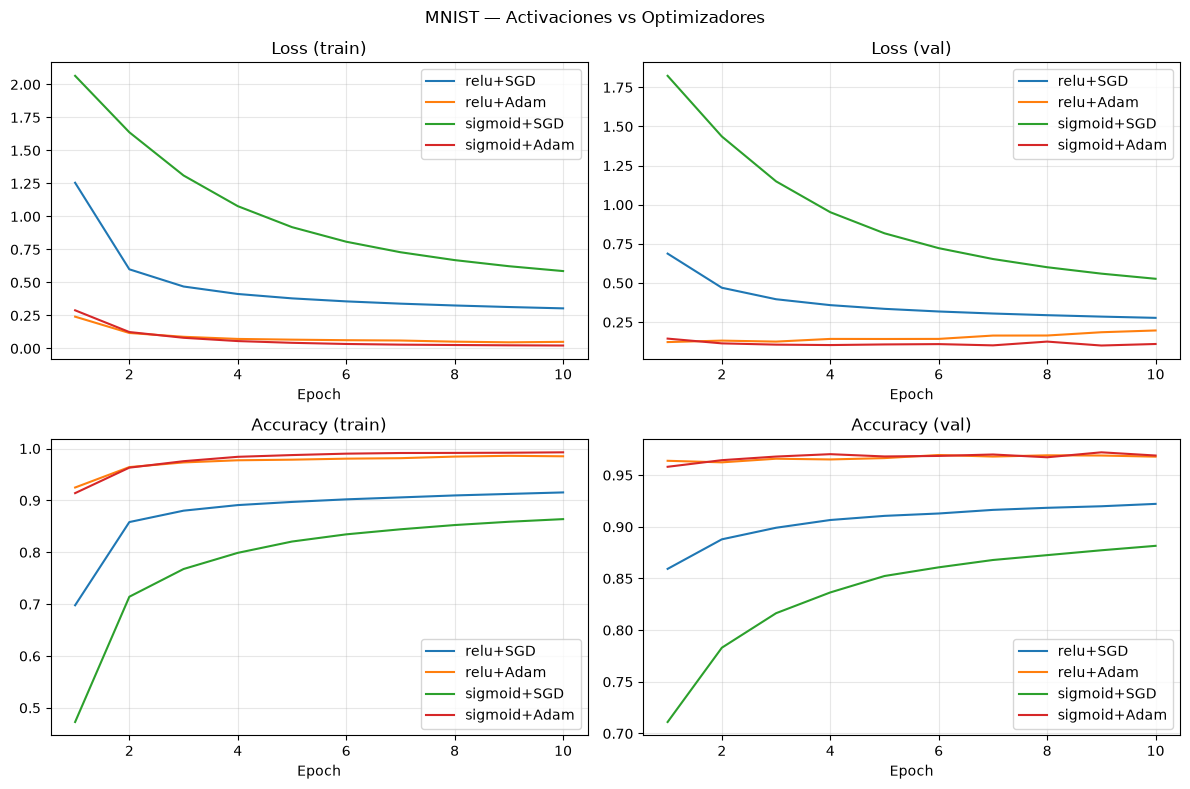

Config            val_acc  val_loss  ep. val_acc>=umbral
relu+SGD           0.9222    0.2777                    4
relu+Adam          0.9679    0.1970                    1
sigmoid+SGD        0.8816    0.5273                nunca
sigmoid+Adam       0.9690    0.1107                    1

🏆 Configuración ganadora (mayor val_acc final): ('sigmoid', 'Adam')


In [6]:
res_mnist = correr_experimentos(x_tr, y_tr, x_val, y_val)
graficar_experimentos(res_mnist, "MNIST — Activaciones vs Optimizadores")
ganador = tabla_resumen(res_mnist, umbral=0.90)
print("\n🏆 Configuración ganadora (mayor val_acc final):", ganador)

### Resultado de la comparación (esta ejecución)

La mejor combinación fue **Sigmoid + Adam**: obtuvo `val_accuracy = 0.9690`, frente a `0.9679` de ReLU + Adam, una diferencia pequeña de **0.0011**. Ambas combinaciones con Adam superaron el 90% ya en el primer epoch. Con SGD, ReLU llegó al umbral en el epoch 4 y Sigmoid no lo alcanzó en 10 epochs (`0.8816`). En estas curvas Adam redujo el loss y aprendió más rápido que SGD; la comparación favorece Adam para esta configuración. No se observó que Sigmoid se quedara estancada cuando se combinó con Adam, aunque sí rindió peor con SGD. La causa probable es que Sigmoid puede saturarse y reducir el gradiente, mientras Adam adapta el tamaño de paso por parámetro.


## 5. Evaluación

In [10]:
def evaluar(modelo, hist, x_te, y_te, nombres):
    # --- Curvas de loss y accuracy (train vs val)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, (tr, va, t) in zip(ax, [("loss", "val_loss", "Loss"), ("accuracy", "val_accuracy", "Accuracy")]):
        a.plot(hist[tr], label="train"); a.plot(hist[va], label="val")
        a.set_title(t); a.set_xlabel("Epoch"); a.legend(); a.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    # --- Accuracy en test
    probs = modelo.predict(x_te, verbose=0)
    pred = probs.argmax(axis=1)
    acc = (pred == y_te).mean()
    print(f"Accuracy en test: {acc:.4f}")

    # --- Matriz de confusión
    cm = tf.math.confusion_matrix(y_te, pred, num_classes=10).numpy()
    plt.figure(figsize=(8, 7)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
    plt.xticks(range(10), nombres, rotation=90); plt.yticks(range(10), nombres)
    for i in range(10):
        for j in range(10):
            plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.xlabel("Predicho"); plt.ylabel("Real"); plt.title("Matriz de confusión (test)")
    plt.tight_layout(); plt.show()

    # --- Aciertos (fila 1) y errores (fila 2)
    ok = np.where(pred == y_te)[0][:5]
    mal = np.where(pred != y_te)[0][:5]
    fig, axes = plt.subplots(2, 5, figsize=(11, 5))
    for fila, (idxs, color) in enumerate([(ok, "green"), (mal, "red")]):
        for col, idx in enumerate(idxs):
            axes[fila, col].imshow(x_te[idx].reshape(28, 28), cmap="gray")
            axes[fila, col].set_title(f"real: {nombres[y_te[idx]]}\npred: {nombres[pred[idx]]}",
                                      color=color, fontsize=9)
            axes[fila, col].axis("off")
    plt.suptitle("Fila 1: aciertos | Fila 2: errores"); plt.tight_layout(); plt.show()

    # --- Análisis del error: el fallo con mayor confianza
    errores = np.where(pred != y_te)[0]
    peor = errores[np.argmax(probs[errores].max(axis=1))]
    top3 = np.argsort(probs[peor])[::-1][:3]
    plt.figure(figsize=(3, 3)); plt.imshow(x_te[peor].reshape(28, 28), cmap="gray"); plt.axis("off")
    plt.title(f"Real: {nombres[y_te[peor]]} | Pred: {nombres[pred[peor]]}"); plt.show()
    print("Top-3 probabilidades:", [(nombres[k], round(float(probs[peor][k]), 3)) for k in top3])
    cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
    i, j = np.unravel_index(cm_off.argmax(), cm_off.shape)
    print(f"Confusión más frecuente: real '{nombres[i]}' → predicho '{nombres[j]}' ({cm_off[i, j]} veces)")
    return acc

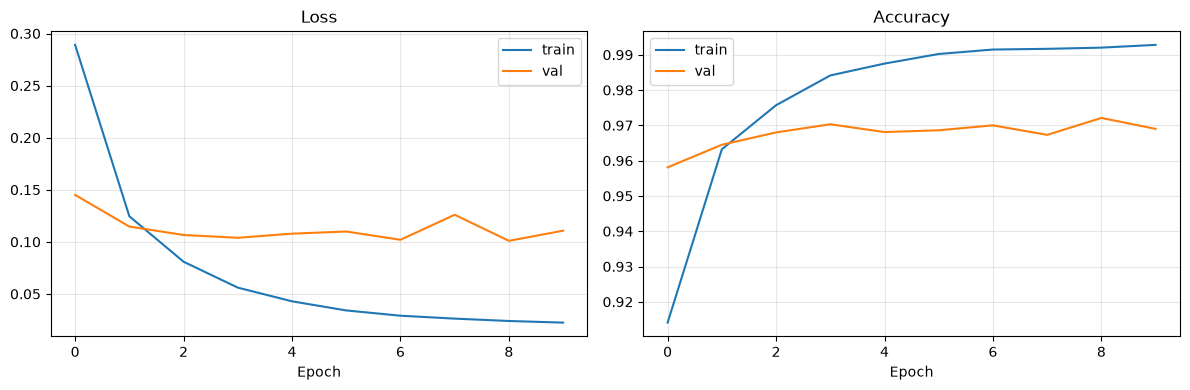

Accuracy en test: 0.9722


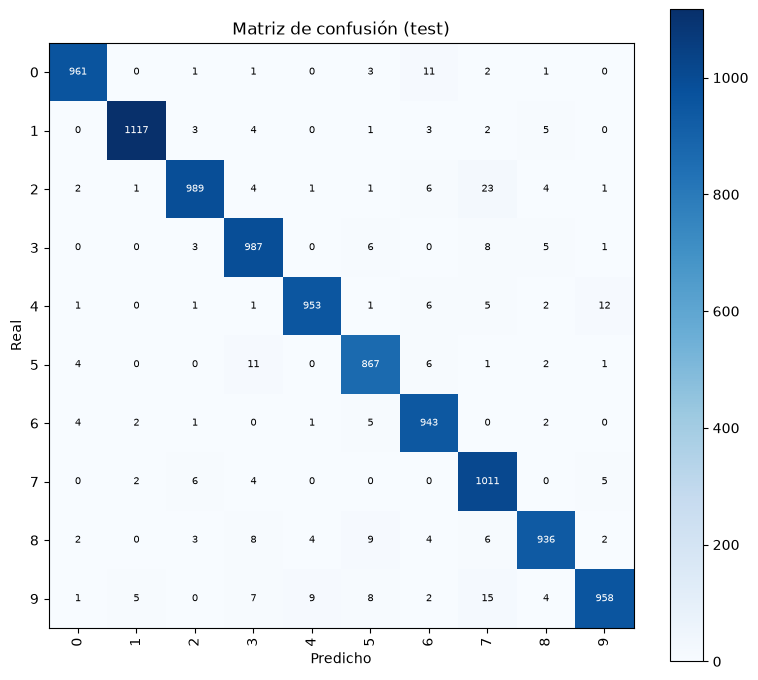

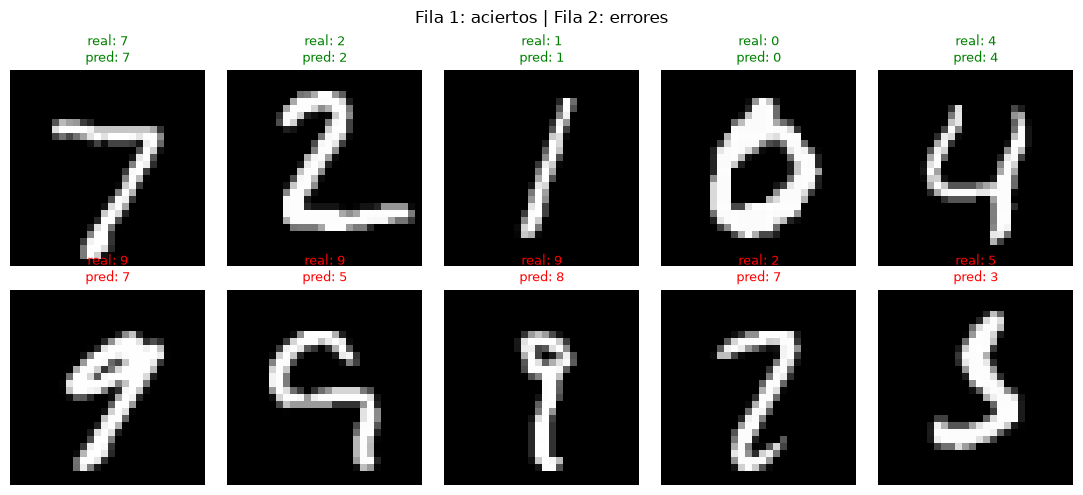

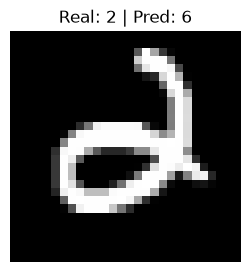

Top-3 probabilidades: [('6', 1.0), ('2', 0.0), ('0', 0.0)]
Confusión más frecuente: real '2' → predicho '7' (23 veces)


In [8]:
modelo_gan, hist_gan = res_mnist[ganador]
acc_mnist = evaluar(modelo_gan, hist_gan, x_te, y_test, nombres_mnist)

### Análisis del error (esta ejecución)

El test alcanzó **97.22% de accuracy**. La matriz muestra que la confusión más frecuente fue el **2 real predicho como 7 (23 casos)**. En el ejemplo de error de mayor confianza, la predicción top fue **6 con probabilidad cercana a 1.0**. Esto sugiere un trazo visualmente ambiguo o poco representativo; una capa densa que recibe los píxeles aplanados puede confundir trazos locales y no aprovecha explícitamente la estructura espacial. La probabilidad alta indica seguridad del modelo, no que la respuesta sea correcta.


## 6. Conclusiones (MNIST)

In [9]:
orden = sorted(res_mnist, key=lambda k: res_mnist[k][1]["val_accuracy"][-1], reverse=True)
segundo = orden[1]
mejor_acc_val = res_mnist[ganador][1]["val_accuracy"][-1]
segundo_acc_val = res_mnist[segundo][1]["val_accuracy"][-1]
acc_train_final = hist_gan["accuracy"][-1]
acc_val_final = hist_gan["val_accuracy"][-1]
print(f"Ganador: {ganador} | val_accuracy={mejor_acc_val:.4f} | test_accuracy={acc_mnist:.4f}")
print(f"Margen sobre {segundo}: {mejor_acc_val-segundo_acc_val:.4f} puntos de accuracy de validación")
print(f"Brecha train-val final: {acc_train_final-acc_val_final:.4f}; revisá las curvas para valorar overfitting.")

Ganador: ('sigmoid', 'Adam') | val_accuracy=0.9690 | test_accuracy=0.9722
Margen sobre ('relu', 'Adam'): 0.0011 puntos de accuracy de validación
Brecha train-val final: 0.0238; revisá las curvas para valorar overfitting.


### Conclusiones (MNIST)

- **Ganador:** Sigmoid + Adam, con `val_accuracy=0.9690`; margen de **0.0011** sobre ReLU + Adam. Su accuracy de test fue **0.9722**.
- **Velocidad:** Adam llegó al 90% de validación en el epoch 1 con ambas activaciones; SGD lo hizo en el epoch 4 con ReLU y no llegó en 10 epochs con Sigmoid.
- **Sobreajuste:** la diferencia final entre accuracy de entrenamiento y validación de la configuración ganadora fue **0.0238**. Hay una brecha moderada; las curvas permiten ver si se abre a lo largo del entrenamiento. No se usaron Dropout ni Early Stopping, así que no se evaluó su efecto.
- **Celda honesta:** Sigmoid + Adam superó a ReLU + Adam por muy poco, aunque la combinación Sigmoid + SGD fue claramente la peor. El resultado depende de combinar activación y optimizador, no de elegir una activación de forma aislada.
- **Qué cambiaría:** añadiría Early Stopping y Dropout en un experimento separado y compararía una CNN, que conserva la relación espacial entre píxeles.
